# DS-06 · Student Performance Analysis (Open Brief)
**Team:** _add names_   |   **Date:** 30 September 2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 50)

# Figures are saved to reports/figures (repo layout) so they can be used in the README and slides
FIG_DIR = Path("../reports/figures") if Path("../data").exists() else Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def find_data(name):
    """Look in data/ first; in Colab without the repo, show a Choose Files button."""
    for p in [Path("../data") / name, Path("data") / name, Path(name)]:
        if p.exists():
            return p
    try:
        from google.colab import files
        print(f"Please upload {name}")
        up = files.upload()
        return Path(list(up.keys())[0])
    except ImportError:
        raise FileNotFoundError(f"Put {name} in the data/ folder")

path = find_data("student-mat.csv")
df_raw = pd.read_csv(path, sep=";")
print("Loaded", path, "→ shape", df_raw.shape)

Loaded ../data/student-mat.csv → shape (395, 33)


## 1. Problem statement
**Client:** a secondary school's academic office that wants to know which students may need extra maths support **before** the final exam.

**Business question:** How do study habits, attendance/absences, previous academic failures, parental education and school support relate to students' final mathematics performance?

- **Task type:** regression. **Target variable:** `G3`, final maths grade (0–20, pass mark 10).
- **Success metric:** **MAE** (mean absolute error, in grade points), with RMSE and R² alongside. The model must beat a **baseline that predicts the average grade** for everyone.
- **Why MAE:** it is in the same unit as the grade ("on average we are off by 2 points"), so teachers can understand it directly. R² shows how much of the grade differences the factors explain.

## 2. Data dictionary
UCI Student Performance (Cortez & Silva, 2008), **Mathematics** file: 395 students × 33 columns from two Portuguese schools. (The separate Portuguese-language file has 649 students and is not used.)

| Column | Meaning | Type | Unit / values | Notes |
|---|---|---|---|---|
| school | School | category | GP / MS | |
| sex, age | Sex, age | category / number | F/M, 15–22 years | |
| address, famsize, Pstatus | Urban/rural, family size, parents together | category | U/R, LE3/GT3, T/A | |
| Medu, Fedu | Mother's / father's education | ordinal | 0 none, 1 primary, 2 5th–9th, 3 secondary, 4 higher | Level 0 has only 2–3 students |
| Mjob, Fjob, reason, guardian | Parents' jobs, reason for school choice, guardian | category | text | |
| traveltime | Home-to-school travel | ordinal | 1 <15 min … 4 >1 h | |
| studytime | Weekly study time | ordinal | 1 <2 h, 2 2–5 h, 3 5–10 h, 4 >10 h | |
| failures | Past class failures | count | 0–3 (3 = 3+) | |
| schoolsup, famsup, paid | Extra school support, family support, paid maths classes | binary | yes/no | |
| activities, nursery, higher, internet, romantic | Extracurricular, attended nursery, wants higher education, internet at home, in a relationship | binary | yes/no | |
| famrel, freetime, goout, health | Family relations, free time, going out, health | ordinal | 1 (very low) – 5 (very high) | Self-reported |
| Dalc, Walc | Weekday / weekend alcohol use | ordinal | 1–5 | Self-reported |
| absences | School absences | count | 0–75 | |
| G1, G2 | 1st and 2nd period grades | number | 0–20 | **Not used as inputs** (see leakage check) |
| G3 | **Final grade (target)** | number | 0–20 | |

## 3. Data audit & cleaning

In [2]:
df = df_raw.copy()
print("Shape:", df.shape, "| Missing cells:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
print("Column types:", df.dtypes.astype(str).value_counts().to_dict())
q1, q3 = df["absences"].quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
print(f"Absence outliers (> {upper:.0f}): {(df['absences'] > upper).sum()}, max {df['absences'].max()}")
df[["age", "absences", "G1", "G2", "G3"]].describe()

Shape: (395, 33) | Missing cells: 0 | Duplicate rows: 0
Column types: {'str': 17, 'int64': 16}
Absence outliers (> 20): 15, max 75


,age,absences,G1,G2,G3
count,395.000,395.000,395.000,395.000,395.000
mean,16.696,5.709,10.909,10.714,10.415
std,1.276,8.003,3.319,3.762,4.581
min,15.000,0.000,3.000,0.000,0.000
25%,16.000,0.000,8.000,9.000,8.000
50%,17.000,4.000,11.000,11.000,11.000
75%,18.000,8.000,13.000,13.000,14.000
max,22.000,75.000,19.000,19.000,20.000


Students with G3 = 0: 38 (9.6%); their absences: min 0, max 0
Their 1st-period grade G1: mean 7.5, range 4–12


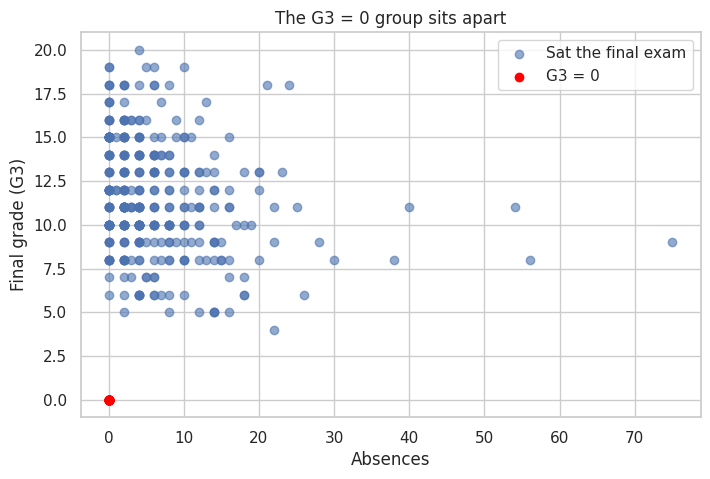

In [3]:
zero = df[df["G3"] == 0]
print(f"Students with G3 = 0: {len(zero)} ({len(zero)/len(df):.1%}); their absences: min {zero['absences'].min()}, max {zero['absences'].max()}")
print(f"Their 1st-period grade G1: mean {zero['G1'].mean():.1f}, range {zero['G1'].min()}–{zero['G1'].max()}")
plt.figure(figsize=(8, 5))
plt.scatter(df.loc[df.G3 > 0, "absences"], df.loc[df.G3 > 0, "G3"], alpha=0.6, label="Sat the final exam")
plt.scatter(zero["absences"], zero["G3"], color="red", label="G3 = 0")
plt.xlabel("Absences"); plt.ylabel("Final grade (G3)"); plt.title("The G3 = 0 group sits apart"); plt.legend()
save_fig("01_g3_zero")

**Insight:** **38 students (9.6%) have G3 = 0, and every one of them has 0 recorded absences**, although many had normal grades earlier (G1 up to 12). A real 0 with perfect attendance is not believable: these students almost certainly **did not sit the final exam** (dropped out or moved).

In [4]:
df["sat_exam"] = (df["G3"] > 0).astype(int)
df["absence_band"] = pd.cut(df["absences"], [-1, 0, 5, 10, 100], labels=["0", "1–5", "6–10", "11+"])
edu = {0: "≤ Primary", 1: "≤ Primary", 2: "5th–9th", 3: "Secondary", 4: "Higher"}
df["Medu_group"], df["Fedu_group"] = df["Medu"].map(edu), df["Fedu"].map(edu)
sat = df[df["sat_exam"] == 1].copy()
print("All:", len(df), "| Sat exam:", len(sat), "| Did not sit:", len(df) - len(sat))

All: 395 | Sat exam: 357 | Did not sit: 38


**Decision log**
| Issue | Decision | Reason |
|---|---|---|
| Missing values / duplicates | None found | – |
| **38 students with G3 = 0 and 0 absences** | **Not deleted**; flagged with `sat_exam`. Grade analysis and the model use the **357 who sat the exam**; the 38 are analysed separately | They did not sit the exam, so their 0 is not a real grade and it hides real patterns; *not sitting* is itself a warning sign |
| Absence outliers (up to 75) | **Kept**, grouped into bands for charts | Real long absences; exactly the students the school needs to see |
| Medu/Fedu level 0 (3 and 2 students) | Merged with level 1 ("≤ Primary") for charts | Averages of 2–3 students are not reliable |
| G1, G2 | Excluded from model inputs | Leakage for an early-support question (section 5) |

## 4. Exploratory data analysis

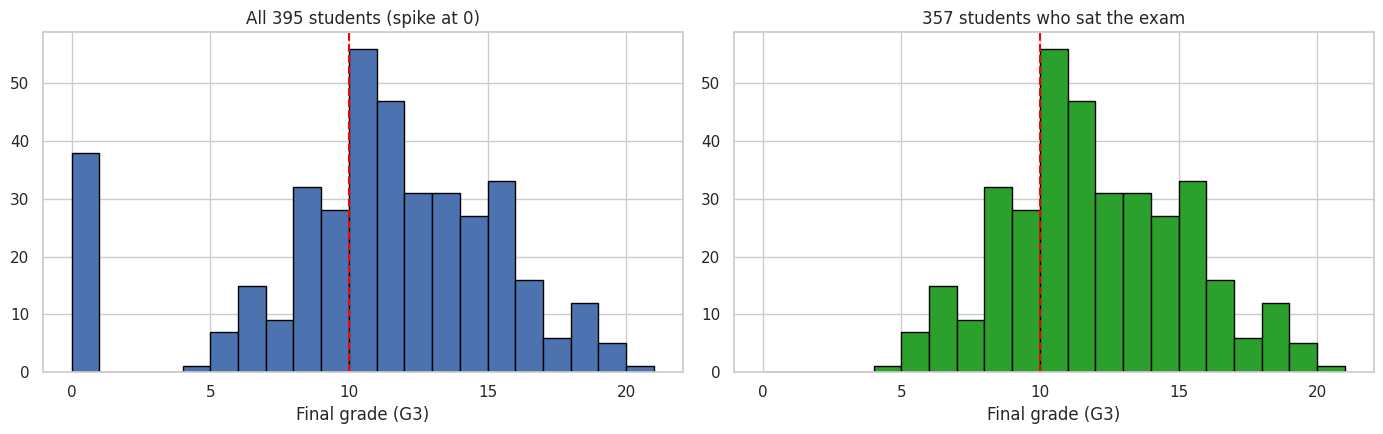

Sat exam: mean 11.52, median 11, below pass mark 10: 25.8%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df["G3"], bins=range(0, 22), edgecolor="black"); axes[0].set_title("All 395 students (spike at 0)")
axes[1].hist(sat["G3"], bins=range(0, 22), edgecolor="black", color="tab:green"); axes[1].set_title("357 students who sat the exam")
for ax in axes: ax.axvline(10, color="red", ls="--"); ax.set_xlabel("Final grade (G3)")
plt.tight_layout(); save_fig("02_grade_distribution")
print(f"Sat exam: mean {sat['G3'].mean():.2f}, median {sat['G3'].median():.0f}, below pass mark 10: {(sat['G3'] < 10).mean():.1%}")

**Insight:** students who sat the exam averaged **11.5/20**, but **26%** scored below the pass mark of 10. Together with the 38 non-sitters, about **a third** of students did not pass.

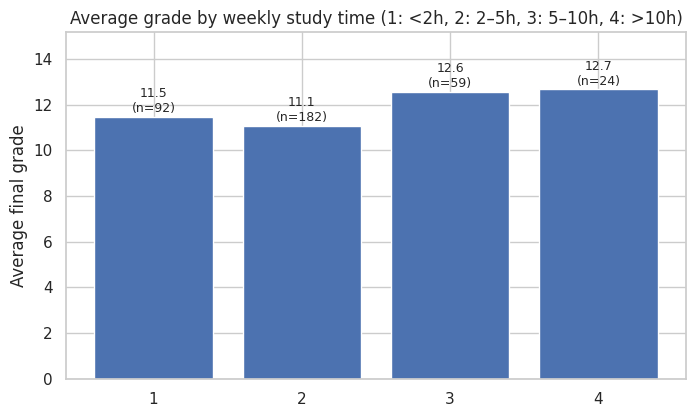

,mean,count
studytime,,
1,11.470,92
2,11.070,182
3,12.560,59
4,12.670,24


In [6]:
def bar_mean(col, order, title, fname, data=sat, ax=None, save=True):
    g = data.groupby(col, observed=True)["G3"].agg(["mean", "count"]).reindex(order)
    ax = ax or plt.subplots(figsize=(8, 4.5))[1]
    bars = ax.bar(g.index.astype(str), g["mean"])
    for b, (m, n) in zip(bars, g.values): ax.text(b.get_x() + b.get_width() / 2, m + 0.2, f"{m:.1f}\n(n={int(n)})", ha="center", fontsize=9)
    ax.set(title=title, ylabel="Average final grade", ylim=(0, g["mean"].max() + 2.5))
    if save: save_fig(fname)
    return g.round(2)
study = bar_mean("studytime", [1, 2, 3, 4], "Average grade by weekly study time (1: <2h, 2: 2–5h, 3: 5–10h, 4: >10h)", "03_studytime"); study

**Insight:** study time helps only **above 5 hours a week**: <2 h 11.5, 2–5 h 11.1, 5–10 h **12.6**, >10 h 12.7 (24 students). The link is weak (r = 0.13).

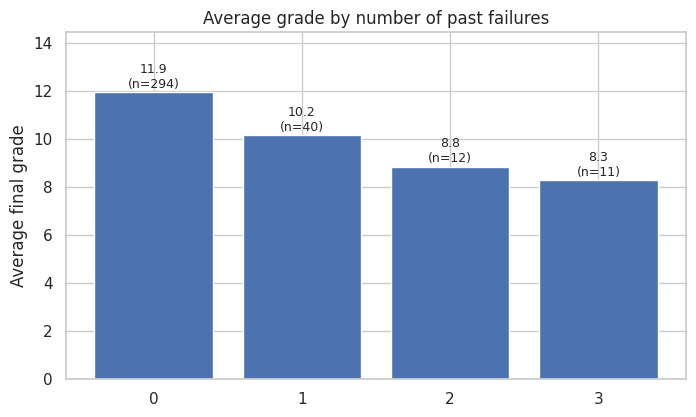

Did NOT sit the final, by past failures: {0: 0.06, 1: 0.2, 2: 0.29, 3: 0.31}


,mean,count
failures,,
0,11.940,294
1,10.150,40
2,8.830,12
3,8.270,11


In [7]:
fail = bar_mean("failures", [0, 1, 2, 3], "Average grade by number of past failures", "04_failures")
print("Did NOT sit the final, by past failures:", (1 - df.groupby("failures")["sat_exam"].mean()).round(2).to_dict()); fail

**Insight:** the **strongest pattern**: 0 failures **11.9** → 1: 10.2 → 2: 8.8 → 3: **8.3**. Past failures also predict *not sitting* the exam: 6% with no failures vs **20–31%** with one or more.

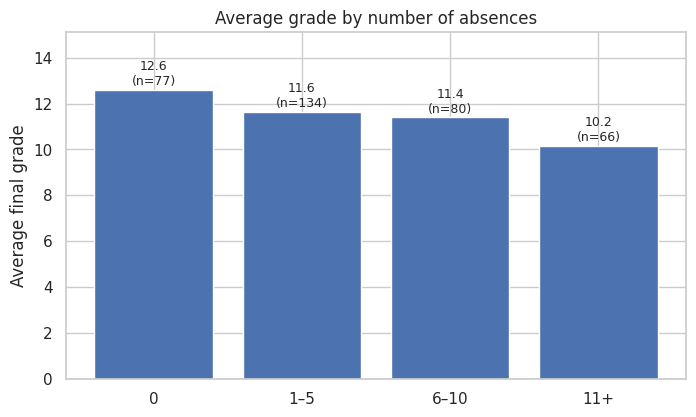

Correlation absences–G3: all students 0.034 | sat exam -0.213


,mean,count
absence_band,,
0,12.610,77
1–5,11.650,134
6–10,11.400,80
11+,10.150,66


In [8]:
absn = bar_mean("absence_band", ["0", "1–5", "6–10", "11+"], "Average grade by number of absences", "05_absences")
print(f"Correlation absences–G3: all students {df['absences'].corr(df['G3']):.3f} | sat exam {sat['absences'].corr(sat['G3']):.3f}"); absn

**Insight:** absences **do** matter: 0 absences **12.6** vs 11+ absences **10.2** (r = −0.21). With the G3 = 0 group included, the correlation looks like +0.03 ("no link"). That was an artefact of the non-sitters.

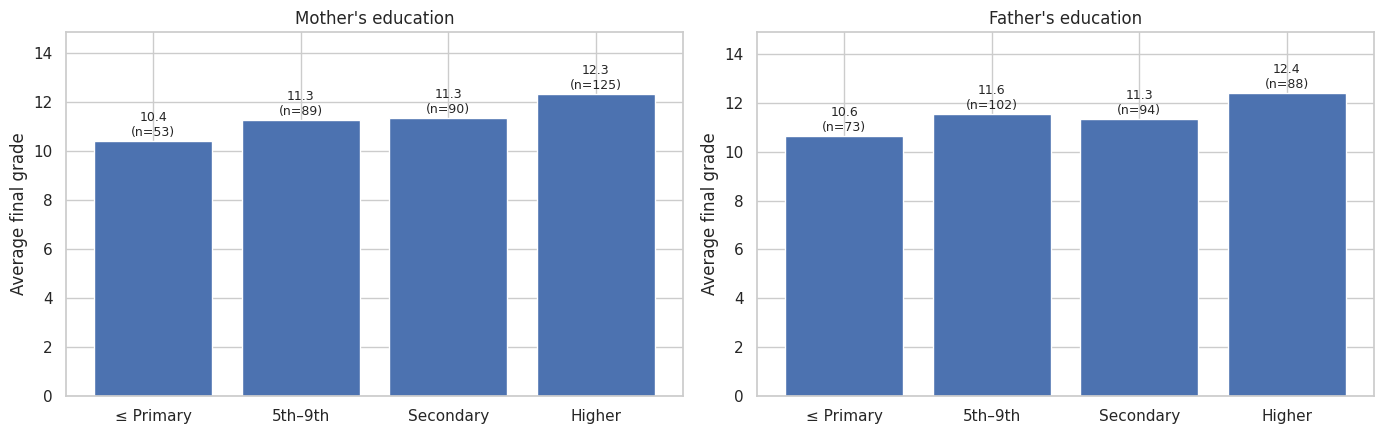

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = ["≤ Primary", "5th–9th", "Secondary", "Higher"]
m_edu = bar_mean("Medu_group", order, "Mother's education", "", ax=axes[0], save=False)
f_edu = bar_mean("Fedu_group", order, "Father's education", "", ax=axes[1], save=False)
plt.tight_layout(); save_fig("06_parent_education")

**Insight:** students whose mother has higher education average **12.3** vs **10.4** for primary or less (fathers: 12.4 vs 10.6). A steady, moderate link.

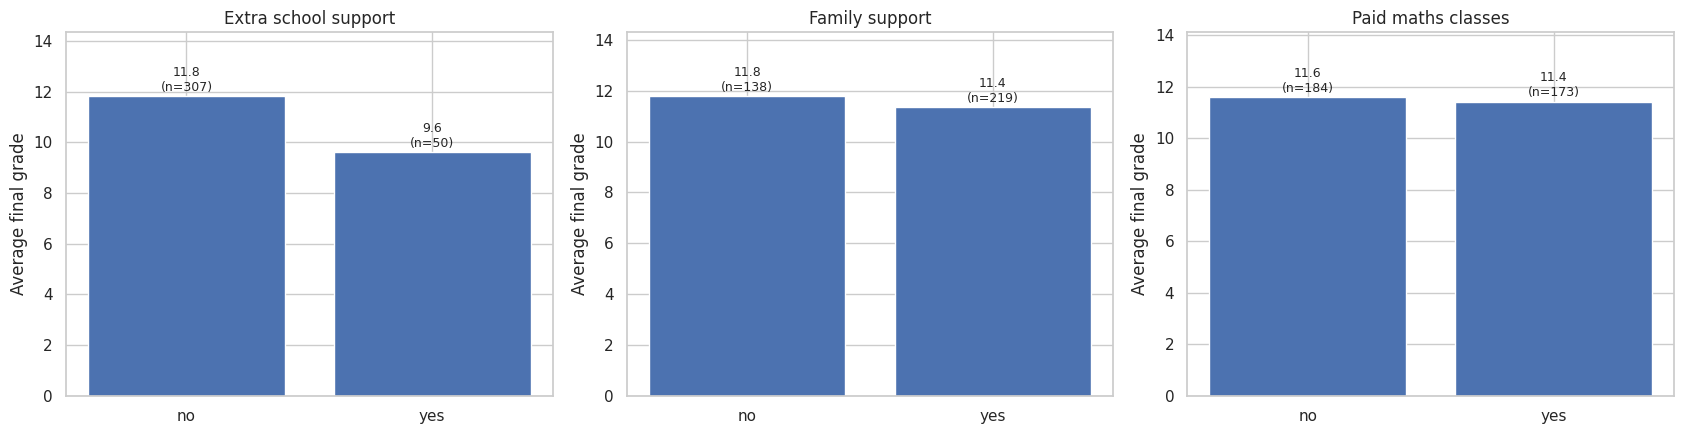

1st-period grade G1 by school support: {'no': 11.62, 'yes': 9.12}
Improvement G3 − G1 by school support: {'no': 0.21, 'yes': 0.5}


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (c, t) in zip(axes, [("schoolsup", "Extra school support"), ("famsup", "Family support"), ("paid", "Paid maths classes")]):
    bar_mean(c, ["no", "yes"], t, "", ax=ax, save=False)
plt.tight_layout(); save_fig("07_support")
print("1st-period grade G1 by school support:", sat.groupby("schoolsup")["G1"].mean().round(2).to_dict())
print("Improvement G3 − G1 by school support:", (sat["G3"] - sat["G1"]).groupby(sat["schoolsup"]).mean().round(2).to_dict())

**Insight:** supported students end lower (**9.6 vs 11.8**) because support goes to students who were **already weaker** (G1 9.1 vs 11.6). From G1 to G3 they improved **+0.50** points vs **+0.21** for others, a small sign that support helps. Family support and paid classes show almost no difference.

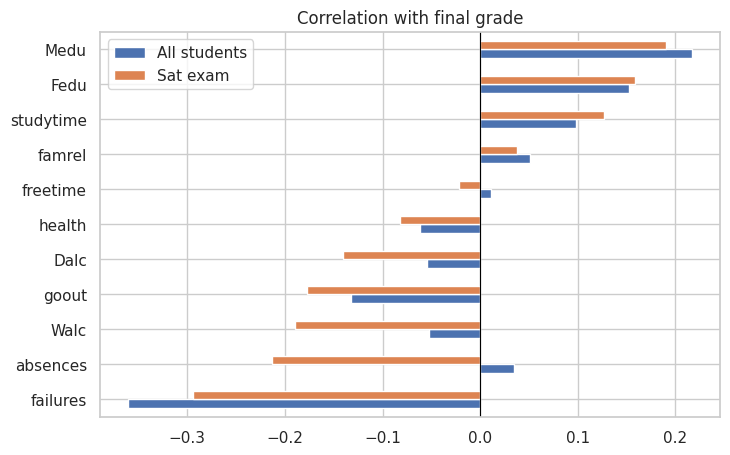

,All students,Sat exam
failures,-0.360,-0.294
absences,0.034,-0.213
Walc,-0.052,-0.190
goout,-0.133,-0.177
Dalc,-0.055,-0.141
health,-0.061,-0.082
freetime,0.011,-0.022
famrel,0.051,0.038
studytime,0.098,0.127
Fedu,0.152,0.159


In [11]:
cols = ["failures", "absences", "Walc", "goout", "Dalc", "health", "freetime", "famrel", "studytime", "Fedu", "Medu"]
c = pd.DataFrame({"All students": df[cols].corrwith(df["G3"]), "Sat exam": sat[cols].corrwith(sat["G3"])}).sort_values("Sat exam")
c.plot.barh(figsize=(8, 5), title="Correlation with final grade"); plt.axvline(0, color="black", lw=0.8); save_fig("08_correlations"); c.round(3)

**Insight:** among students who sat the exam, grades fall with **failures (−0.29)**, **absences (−0.21)**, weekend drinking (−0.19) and going out (−0.18), and rise with parents' education and study time. Removing the non-sitters changes absences the most.

## 5. Feature preparation

In [12]:
target = "G3"
features = ["school", "sex", "age", "address", "famsize", "Pstatus", "Medu", "Fedu", "Mjob", "Fjob", "reason", "guardian",
            "traveltime", "studytime", "failures", "schoolsup", "famsup", "paid", "activities", "nursery", "higher",
            "internet", "romantic", "famrel", "freetime", "goout", "Dalc", "Walc", "health", "absences"]
X, y = sat[features], sat[target]
cat_features = [c for c in features if not pd.api.types.is_numeric_dtype(X[c])]
num_features = [c for c in features if c not in cat_features]
preprocessor = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_features), ("num", "passthrough", num_features)])
print(f"{len(cat_features)} categorical (one-hot) + {len(num_features)} numeric features")

17 categorical (one-hot) + 13 numeric features


- **Encoding:** 17 yes/no and text columns → one-hot. **Scaling:** not needed for a Random Forest.
- **Rows:** the 357 students who sat the exam (a predicted grade only makes sense for them).
- **Leakage check:** **G1 and G2 are excluded.** They are grades from the same school year, correlated ~0.9 with G3, and not available at the start of the year when support must be planned. Every remaining input is known at the start of the year. The one-hot encoder is fitted inside the pipeline, on training data only.

## 6. Modelling

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
model = Pipeline([("prep", preprocessor), ("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42))]).fit(X_train, y_train)
pred_base, pred = baseline.predict(X_test), model.predict(X_test)
def row(name, p): return {"Model": name, "MAE": mean_absolute_error(y_test, p), "RMSE": np.sqrt(mean_squared_error(y_test, p)), "R²": r2_score(y_test, p)}

- **Baseline:** predict the training-set average grade for everyone.
- **Improved model:** Random Forest (300 trees, `min_samples_leaf=3` to limit overfitting). It handles many mixed features and non-linear effects (e.g. study time only helping above 5 h) without manual transformations.

## 7. Evaluation

In [14]:
cv = KFold(5, shuffle=True, random_state=42)
cv_rf = -cross_val_score(model, X, y, cv=cv, scoring="neg_mean_absolute_error")
cv_b = -cross_val_score(baseline, X, y, cv=cv, scoring="neg_mean_absolute_error")
results = pd.DataFrame([row("Baseline (average)", pred_base), row("Random Forest", pred)]).set_index("Model")
results["5-fold CV MAE"] = [f"{cv_b.mean():.2f} ± {cv_b.std():.2f}", f"{cv_rf.mean():.2f} ± {cv_rf.std():.2f}"]
results

,MAE,RMSE,R²,5-fold CV MAE
Model,,,,
Baseline (average),2.572,3.106,-0.001,2.63 ± 0.11
Random Forest,2.194,2.708,0.239,2.34 ± 0.12


**Result:** the model is off by **2.19 grade points** on average vs **2.57** for the baseline (15% better; cross-validated 2.34 vs 2.63), with R² = **0.24**. Background factors explain about a quarter of grade differences: useful for **flagging** students, not for predicting an exact grade.

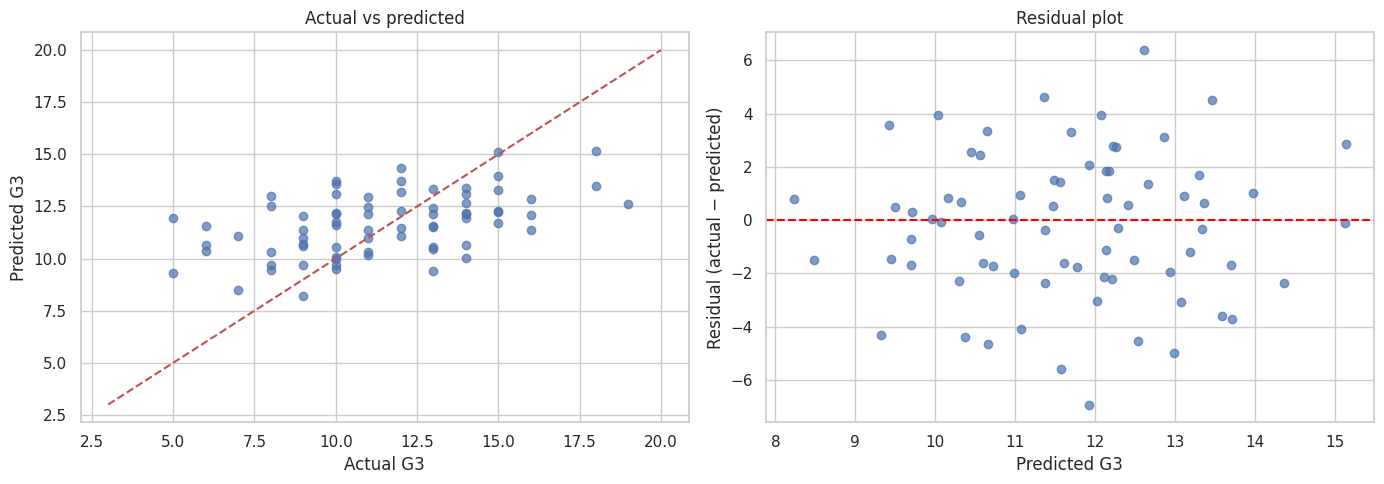

In [15]:
resid = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, pred, alpha=0.7); lims = [3, 20]; axes[0].plot(lims, lims, "r--")
axes[0].set(xlabel="Actual G3", ylabel="Predicted G3", title="Actual vs predicted")
axes[1].scatter(pred, resid, alpha=0.7); axes[1].axhline(0, color="red", ls="--")
axes[1].set(xlabel="Predicted G3", ylabel="Residual (actual − predicted)", title="Residual plot")
plt.tight_layout(); save_fig("09_residuals")

In [16]:
err = sat.loc[X_test.index].assign(pred=pred.round(1), error=resid.round(1))
print("Mean error by actual grade band:")
print(err.groupby(pd.cut(err["G3"], [0, 9, 13, 20], labels=["<10 (fail)", "10–13", "14–20"]), observed=True)["error"].agg(["count", "mean"]).round(2))
err.reindex(err["error"].abs().sort_values(ascending=False).index)[["G3", "pred", "error", "failures", "absences", "studytime", "schoolsup"]].head(6)

Mean error by actual grade band:
            count   mean
G3                      
<10 (fail)     19 -3.000
10–13          33 -0.390
14–20          20  2.640


,G3,pred,error,failures,absences,studytime,schoolsup
373,5,11.900,-6.900,0,14,1,no
113,19,12.600,6.400,0,10,1,no
82,6,11.600,-5.600,0,10,2,no
90,8,13.000,-5.000,0,0,3,no
203,6,10.700,-4.700,0,18,1,no
391,16,11.400,4.600,0,3,1,no


**Error analysis:** the model **pulls every prediction towards the average**. Students who actually failed (< 10) are predicted **3.0 points too high**, and top students (14–20) **2.6 points too low**. The biggest misses (e.g. a student with G3 = 5 predicted 11.9) have **no past failures and no school support**: nothing in their background data warns of trouble. **Business meaning:** a predicted grade of 11 can hide a failing student, so the school should flag everyone predicted **below about 12**, not below 10, and combine the model with mid-year grades.

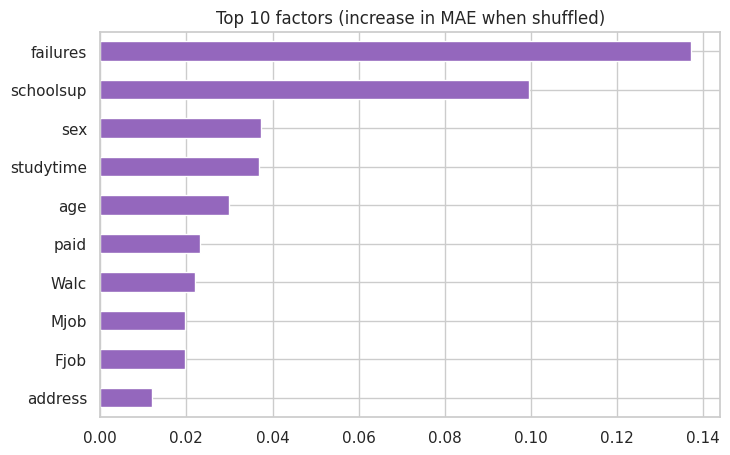

failures    0.137
schoolsup   0.100
sex         0.037
studytime   0.037
age         0.030
paid        0.023
Walc        0.022
Mjob        0.020
Fjob        0.020
address     0.012
dtype: float64

In [17]:
perm = permutation_importance(model, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=30, random_state=42)
imp = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)
imp.head(10).sort_values().plot.barh(figsize=(8, 5), color="tab:purple", title="Top 10 factors (increase in MAE when shuffled)")
save_fig("10_importance"); imp.head(10).round(3)

**Insight:** **past failures** are by far the most important factor, followed by **school support** (which marks students the school already sees as weak), then sex, study time and age.

## 8. Conclusion & recommendation
**Answer to the business question**
- **Previous failures** are the strongest warning sign (11.9 → 8.3 average grade; 3–5× more likely to skip the final exam).
- **Absences** matter once non-sitters are removed (12.6 with 0 absences vs 10.2 with 11+).
- **Study time** helps only above 5 hours a week; **parents' education** has a moderate link (mother higher education 12.3 vs 10.4).
- **School support** goes to weaker students and they improve slightly more during the year (+0.50 vs +0.21).
- About **10% of students did not sit the final exam**, mostly those with past failures.
- The model predicts grades within ~2.2 points (15% better than the baseline), explaining a quarter of grade differences.

**Recommendations (each linked to a finding)**
1. **Early-warning list:** students with any past failure get support from the first week.
2. **Attendance alert** at about 10 absences.
3. **Follow up students who stop coming** before the final exam.
4. **Supervised study sessions** so students reach 5+ hours a week.
5. **Keep school support** and judge it by G1 → G3 improvement, not by final grades.
6. Use parental education only as context, never as a label about a student.

**Limitations:** observational data from two Portuguese schools (2005–06); many answers are self-reported; "did not sit" is an assumption the school should confirm; small sample (357) and R² 0.24; the model uses sex, so fairness must be checked before any real use.

**Model use:** because predictions are pulled towards the average, flag students predicted below ~12.

**Next steps:** confirm the G3 = 0 cases with the school; add mid-year data (e.g. G1) for a second, more accurate warning point; test a classification model for "will fail (G3 < 10)".

### Viva notes
1. **Why remove G3 = 0 from the grade analysis?** 38 students had 0 and 0 absences: they did not sit the exam. Keeping them hid the absence effect (+0.03 → −0.21).
2. **Why no G1/G2?** Leakage for an early-warning tool: they are nearly the final grade and not known at the start of the year.
3. **Why MAE?** It is in grade points, so teachers understand it; we compare with a baseline (2.19 vs 2.57).
4. **Why does school support look negative?** Selection: weaker students get support (G1 9.1 vs 11.6); their improvement is actually larger.
5. **Is R² 0.24 good enough?** For flagging, yes; for predicting an exact grade, no.